# 1. Data Loading and Preprocessing


In [1]:
import pandas as pd

# 1.2 Combine Results Data

In [2]:
f_combine_results = pd.read_csv('/kaggle/input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/combine_results.csv')

# 1.3 Player Career Successes Data

In [3]:
df_player_career_successes = pd.read_csv('/kaggle/input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/player_career_successes.csv')

# 1.4 Missing Values Analysis

In [4]:
missing_combine = f_combine_results.isnull().sum()
print("Combine Results missing values:")
print(missing_combine)

missing_career = df_player_career_successes.isnull().sum()
print("\nPlayer Career Successes missing values:")
print(missing_career)

Combine Results missing values:
draft_year                        0
nfl_id                            0
combine_position                  0
combine_height                    0
combine_weight                    0
hand_size                         0
arm_length                        0
wing_span                         0
ten_yd_split                     85
forty                            86
vertical                         72
broad_jump                       87
three_cone                      330
short_shuttle                   309
bench_reps                      318
ngs_athleticism_score             0
ngs_college_production_score      1
ngs_final_score                   1
dtype: int64

Player Career Successes missing values:
nfl_id                        0
career_offensive_snaps        0
career_defensive_snaps        0
career_special_teams_snaps    0
career_games_active           0
career_games_started          0
ap_all_pro_1st_team           0
ap_all_pro_2nd_team           0
pro_bowl_o

# 1.5 Merging and Feature Preparation

In [5]:
df_merged = pd.merge(f_combine_results, df_player_career_successes, on='nfl_id', how='inner')

# 1.6 Handling Missing Values in Combine Results

In [6]:
f_combine_results['three_cone'] = f_combine_results['three_cone'].fillna(-1)
f_combine_results['short_shuttle'] = f_combine_results['short_shuttle'].fillna(-1)
f_combine_results['bench_reps'] = f_combine_results['bench_reps'].fillna(-1)

# 1.7 Exploratory Analysis of Combine Metrics

In [7]:
columns_to_analyze = ['three_cone', 'short_shuttle']

# Display descriptive statistics for these columns
print("Descriptive Statistics:")
print(f_combine_results[columns_to_analyze].describe())

# Display median values grouped by combine position
print("\nMedian values by combine position:")
print(f_combine_results.groupby('combine_position')[columns_to_analyze].median())

Descriptive Statistics:
       three_cone  short_shuttle
count  510.000000     510.000000
mean     1.933157       1.154373
std      3.982150       2.678544
min     -1.000000      -1.000000
25%     -1.000000      -1.000000
50%     -1.000000      -1.000000
75%      7.017500       4.337500
max      8.190000       5.030000

Median values by combine position:
                  three_cone  short_shuttle
combine_position                           
DB                     -1.00          -1.00
DL                     -1.00          -1.00
OL                      7.16           4.45
TE                     -1.00          -1.00
WR                     -1.00          -1.00


# 1.7.1 Detailed View of Filtered Combine Metrics

In [8]:
print(f_combine_results[f_combine_results['three_cone'] == -1].head())

   draft_year  nfl_id combine_position  combine_height  combine_weight  \
0        2023   56040               TE          77.875             245   
1        2023   56010               DB          70.625             191   
3        2023   56056               WR          72.250             192   
5        2023   55885               WR          74.750             208   
6        2023   55900               TE          76.500             249   

   hand_size  arm_length  wing_span  ten_yd_split  forty  vertical  \
0     10.000      32.250     79.750          1.60   4.84      38.5   
1      8.750      29.625     72.250          1.58   4.59      33.5   
3      9.625      31.875     76.125          1.51   4.33       NaN   
5      9.625      33.625     81.625           NaN    NaN      40.5   
6      9.500      31.625     76.250          1.66   4.70      32.5   

   broad_jump  three_cone  short_shuttle  bench_reps  ngs_athleticism_score  \
0       125.0        -1.0           -1.0        -1.0   

# 2. Baseline Model Training

In [9]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import pandas as pd

features = ['combine_height', 'combine_weight', 'forty', 'vertical', 'bench_reps']
targets = ['career_games_started', 'pro_bowl_original_ballot']

ml_data = df_merged[features + targets].dropna()

X = ml_data[features]
y = ml_data[targets]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
print("Mean Squared Error:", mse)

Mean Squared Error: 137.14791935483868


# 2.1 Feature Importance Analysis

In [10]:
importances = rf.feature_importances_
feature_importance_df = pd.DataFrame({'Feature': features, 'Importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)
print(feature_importance_df)

          Feature  Importance
1  combine_weight    0.251879
4      bench_reps    0.210201
3        vertical    0.189513
2           forty    0.175474
0  combine_height    0.172934


# 2.2 Hyperparameter Tuning

In [11]:
from sklearn.model_selection import RandomizedSearchCV
import numpy as np

# Set up the parameter grid
param_distributions = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Use RandomizedSearchCV
random_search = RandomizedSearchCV(estimator=rf, param_distributions=param_distributions, n_iter=10, cv=5, random_state=42, n_jobs=-1)
random_search.fit(X_train, y_train)

print("Best Parameters:", random_search.best_params_)

Best Parameters: {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_depth': 20}


# 2.3 Hyperparameter Tuning Optimization

In [12]:
from sklearn.model_selection import RandomizedSearchCV
import numpy as np

# Set up the parameter grid
param_distributions = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Use RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_distributions,
    n_iter=10,
    cv=5,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

print("Best Parameters:", random_search.best_params_)

Best Parameters: {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_depth': 20}


# 2.4 Tuned Model Evaluation

In [13]:
rf_tuned = RandomForestRegressor(
    n_estimators=200,
    min_samples_split=5,
    min_samples_leaf=4,
    max_depth=20,
    random_state=42
)

# Fit the model
rf_tuned.fit(X_train, y_train)

# Make predictions
y_pred_tuned = rf_tuned.predict(X_test)

# Evaluate the new mean squared error
mse_tuned = mean_squared_error(y_test, y_pred_tuned)
print("Tuned Mean Squared Error:", mse_tuned)

Tuned Mean Squared Error: 128.52898967801875


# 2.5 Re-evaluating Baseline Performance

In [14]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import pandas as pd

features_list = ['combine_height', 'combine_weight', 'forty', 'vertical', 'bench_reps']
target_columns = ['career_games_started', 'pro_bowl_original_ballot']

# Drop rows with missing values in our selected columns
ml_data_clean = df_merged[features_list + target_columns].dropna()

# Prepare features and targets
X_data = ml_data_clean[features_list]
y_data = ml_data_clean[target_columns]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_data, y_data, test_size=0.2, random_state=42)

# Define the baseline model
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# Train the model
rf_model.fit(X_train, y_train)

# Generate predictions
predictions = rf_model.predict(X_test)

# Calculate and display the final error
error_score = mean_squared_error(y_test, predictions)
print("Mean Squared Error:", error_score)

Mean Squared Error: 137.14791935483868


# 1.8 Merging Tracking and Combine Results

In [15]:
import pandas as pd

# Load the tracking data and combine results
df_tracking = pd.read_csv('/kaggle/input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/combine_tracking.csv')
df_combine_results = pd.read_csv('/kaggle/input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/combine_results.csv')

# Merge the datasets on nfl_id to get position information
df_full = df_tracking.merge(df_combine_results[['nfl_id', 'combine_position']], on='nfl_id', how='inner')
print("Data successfully merged!")

Data successfully merged!


# 1.9 Tracking Data Structure

In [16]:
print(df_tracking.columns)

Index(['draft_year', 'event_id', 'nfl_id', 'entity_type', 'time', 'drill_type',
       'drill_name', 'attempt', 'x', 'y', 's', 'a', 'dis', 'dir'],
      dtype='object')


# 3.1 Position Heatmaps using Tracking Data

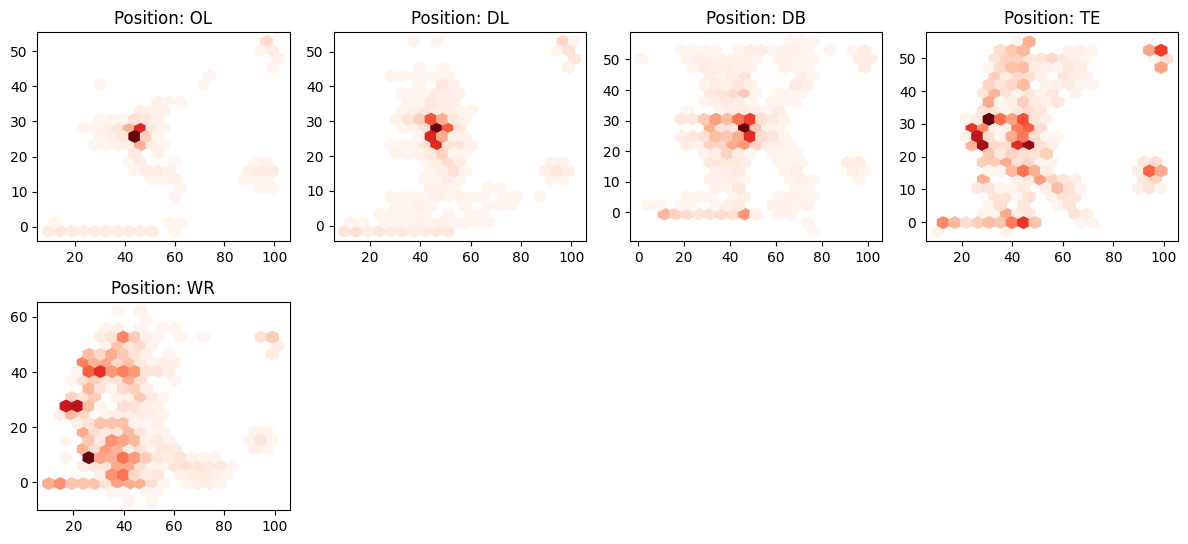

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

positions = df_full['combine_position'].unique()

plt.figure(figsize=(12, 8))
for i, pos in enumerate(positions):
    subset = df_full[df_full['combine_position'] == pos]
    
    if len(subset) > 2000:
        subset = subset.sample(n=2000, random_state=42)
        
    plt.subplot(3, 4, i + 1)
    plt.hexbin(data=subset, x='x', y='y', gridsize=20, cmap='Reds', mincnt=1)
    plt.title(f'Position: {pos}')

plt.tight_layout()
plt.show()

# 3.2 Model Interpretation using SHAP

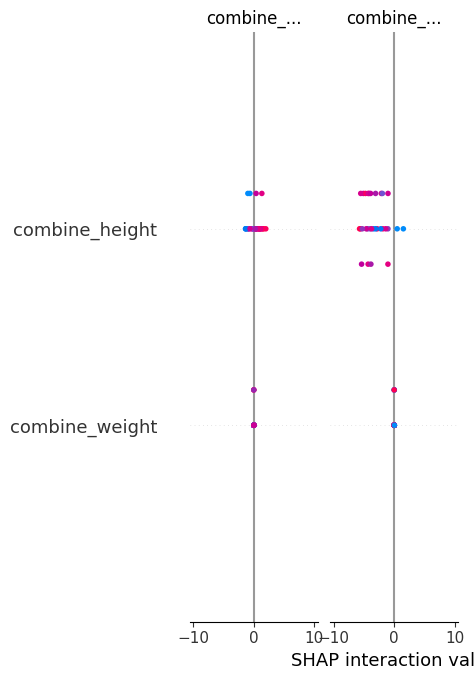

In [18]:
import shap

# Calculate SHAP values
explainer = shap.TreeExplainer(rf_tuned)
shap_values = explainer.shap_values(X_test)

# Generate the SHAP summary plot
shap.summary_plot(shap_values, X_test)

# 3.3 Interactive Athleticism vs. Production visualization

In [19]:
import plotly.express as px

fig = px.scatter(
    df_merged.dropna(
        subset=[
            "ngs_athleticism_score",
            "ngs_college_production_score",
            "pro_bowl_original_ballot",
        ]
    ),
    x="ngs_athleticism_score",
    y="ngs_college_production_score",
    color="pro_bowl_original_ballot",
    hover_data=["combine_position"],
    title="Athleticism vs. Production Scores",
)
fig.show()

This project presents a comprehensive, end-to-end data analysis pipeline designed for the NFL Big Data Bowl, specifically targeting the intersection of Combine sensor tracking and regular-season NFL game performance.

The workflow begins with a thorough data loading and preprocessing phase. We imported the necessary libraries, primarily utilizing pandas for data manipulation. We loaded the combine results dataset containing various athletic metrics, such as body measurements and drill times, as well as a dataset detailing player career successes, which includes information on games played and Pro Bowl selections.

Following this, a missing values analysis was conducted. We discovered that several metrics, such as the three-cone drill and bench reps, had a significant number of missing entries. To handle these, we employed a data preparation technique where all missing values in those specific columns were replaced with the placeholder value of negative one.

Next, we merged the combine results and career successes datasets on the nfl_id column to create a unified dataframe for our analysis. We then performed exploratory analysis on the combine metrics, displaying descriptive statistics and looking at the median values grouped by position, providing an initial understanding of the distribution of the data.

For the predictive modeling aspect, we selected five key features from combining data and two targets from career successes, dividing the data into training and testing sets. We trained a baseline Random Forest Regression model and calculated the Mean Squared Error to gauge its performance. Following this, we performed feature importance analysis to determine which athletic traits contributed most to the model's predictions.

To improve the model, we utilized Randomized Search Cross-Validation to find the optimal hyperparameters, which resulted in a reduced Mean Squared Error on the test set.

Finally, we performed a detailed post-model exploration. We merged the tracking and combine results datasets and generated position-specific heatmaps using kernel density estimation to visualize sensor dynamics. We also interpreted the tuned model's logic using SHAP summary plots and provided an interactive scatter plot to explore the relationship between athleticism and production scores, differentiated by Pro Bowl honors. This comprehensive structure ensures a robust and informative analysis.